In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)


In [2]:
POLLUTANTS = ["pm25", "pm10"]
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
TEST_FRACTION = 0.2

WEATHER_MODES = {
    "same_day": "same-day observed weather (nowcast / association)",
    "t_minus_1": "weather from day t-1 (true forecast)",
}


In [3]:
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")


In [4]:
def get_weather_cols(df):
    return [
        col for col in df.columns
        if (col.startswith(("temperature", "relative_humidity", "dew_point",
                            "apparent_temperature", "pressure", "surface_pressure",
                            "precipitation", "rain_sum", "snowfall", "cloud_cover",
                            "shortwave", "direct_radiation", "diffuse_radiation",
                            "global_tilted", "sunshine", "wind", "et0",
                            "weather_code", "snow_depth", "vapour_pressure", "soil_"))
            and col != "wind_category")
    ]


In [5]:
def load_weather_daily(weather_cols):
    hourly = pd.read_parquet(RAW_DIR / "weather_hourly_skopje_2016_2025.parquet")
    hourly["date"] = pd.to_datetime(hourly["time"]).dt.normalize()

    def mode_or_nan(values):
        values = values.dropna()
        return values.mode().iloc[0] if not values.empty else np.nan

    stat_funcs = {"mean": "mean", "min": "min", "max": "max", "sum": "sum", "mode": mode_or_nan}

    agg_map = {}
    for daily_col in weather_cols:
        base, _, stat = daily_col.rpartition("_")
        if stat in stat_funcs and base in hourly.columns:
            agg_map[daily_col] = (base, stat_funcs[stat])

    missing = [col for col in weather_cols if col not in agg_map]
    if missing:
        raise ValueError(f"Cannot rebuild from raw hourly weather: {missing}")

    weather_daily = (
        hourly.groupby("date")
        .agg(**{name: pd.NamedAgg(col, func) for name, (col, func) in agg_map.items()})
        .sort_index()
    )
    return weather_daily


In [6]:
def build_feature_matrix(df, pollutant, weather_mode, weather_daily):
    lag_cols = [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS]
    rolling_cols = [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS]
    rolling_std_cols = [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS]
    calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
    weather_cols = get_weather_cols(df)

    base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
    required = base_cols + ["date", "station_id", pollutant]

    if weather_mode == "t_minus_1":
        lagged = weather_daily.shift(1, freq="D")
        df = df.drop(columns=weather_cols + ["rain_indicator", "wind_category"])
        df = df.merge(lagged[weather_cols], left_on="date", right_index=True, how="left")
        df["rain_indicator"] = (df["precipitation_sum"] > 0).astype(int)
        df["wind_category"] = pd.cut(df["wind_speed_10m_mean"], bins=[-np.inf, 2, 5, np.inf],
                                     labels=["weak", "moderate", "strong"])

    model_df = df.dropna(subset=required).copy().reset_index(drop=True)
    model_df = model_df.sort_values("date").reset_index(drop=True)

    wind_dummies = pd.get_dummies(model_df["wind_category"], prefix="wind")
    X = pd.concat([model_df[base_cols].reset_index(drop=True), wind_dummies.reset_index(drop=True)], axis=1).astype(float)
    y = model_df[f"{pollutant}_high"].astype(int)

    return model_df, X, y


In [7]:
def chronological_split(model_df, X, y):
    cutoff = model_df["date"].quantile(1 - TEST_FRACTION)
    split_idx = int((model_df["date"] < cutoff).sum())

    shared_dates = set(model_df["date"].iloc[:split_idx]) & set(model_df["date"].iloc[split_idx:])
    train_share = split_idx / len(model_df)

    print(f"Modelling rows: {len(model_df):,}  ({train_share:.0%} train / {1 - train_share:.0%} test)")
    print(f"Positive (high) rate overall: {y.mean():.3f}")
    print(f"Positive rate test: {y.iloc[split_idx:].mean():.3f}")
    print(f"Train period: {model_df['date'].iloc[0].date()} .. {model_df['date'].iloc[split_idx-1].date()}")
    print(f"Test period : {model_df['date'].iloc[split_idx].date()} .. {model_df['date'].iloc[-1].date()}")
    print(f"Dates shared across train/test: {len(shared_dates)} (split is by whole dates, cutoff={pd.Timestamp(cutoff).date()})")

    return X.iloc[:split_idx], X.iloc[split_idx:], y.iloc[:split_idx], y.iloc[split_idx:], split_idx


In [8]:
def evaluate_classification(y_true, y_pred, y_proba):
    return {
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "F1": float(f1_score(y_true, y_pred, zero_division=0)),
        "ROC_AUC": float(roc_auc_score(y_true, y_proba)),
    }


In [9]:
data = {}

for pollutant in POLLUTANTS:
    df = pd.read_parquet(PROCESSED_DIR / f"features_{pollutant}.parquet")
    df["date"] = pd.to_datetime(df["date"])
    weather_daily = load_weather_daily(get_weather_cols(df))

    for weather_mode in WEATHER_MODES:
        model_df, X, y = build_feature_matrix(df, pollutant, weather_mode, weather_daily)
        data[(pollutant, weather_mode)] = {"model_df": model_df, "X": X, "y": y}
        print(f"{pollutant.upper()} [{weather_mode}]: {len(model_df):,} rows, {X.shape[1]} features, {y.mean():.3f} high-pollution rate")

    n_rows = {mode: len(data[(pollutant, mode)]["model_df"]) for mode in WEATHER_MODES}
    print(f"{pollutant.upper()}: rows identical across weather modes = {len(set(n_rows.values())) == 1}")


PM25 [same_day]: 1,912 rows, 59 features, 0.336 high-pollution rate
PM25 [t_minus_1]: 1,912 rows, 59 features, 0.336 high-pollution rate
PM25: rows identical across weather modes = True


PM10 [same_day]: 3,575 rows, 59 features, 0.301 high-pollution rate
PM10 [t_minus_1]: 3,575 rows, 59 features, 0.301 high-pollution rate
PM10: rows identical across weather modes = True


In [10]:
for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        print(f"\n{pollutant.upper()} | {WEATHER_MODES[weather_mode]}")

        entry = data[(pollutant, weather_mode)]
        X_train, X_test, y_train, y_test, split_idx = chronological_split(entry["model_df"], entry["X"], entry["y"])
        entry.update({"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test, "split_idx": split_idx})



PM25 | same-day observed weather (nowcast / association)
Modelling rows: 1,912  (80% train / 20% test)
Positive (high) rate overall: 0.336
Positive rate test: 0.316
Train period: 2018-04-26 .. 2024-07-18
Test period : 2024-07-19 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, cutoff=2024-07-19)

PM25 | weather from day t-1 (true forecast)
Modelling rows: 1,912  (80% train / 20% test)
Positive (high) rate overall: 0.336
Positive rate test: 0.316
Train period: 2018-04-26 .. 2024-07-18
Test period : 2024-07-19 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, cutoff=2024-07-19)

PM10 | same-day observed weather (nowcast / association)
Modelling rows: 3,575  (80% train / 20% test)
Positive (high) rate overall: 0.301
Positive rate test: 0.166
Train period: 2016-12-18 .. 2024-03-06
Test period : 2024-03-07 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, cutoff=2024-03-07)

PM10 | weather from day t-1 (true forecast)

In [11]:
for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        entry = data[(pollutant, weather_mode)]
        scaler = StandardScaler().fit(entry["X_train"])

        entry["scaler"] = scaler
        entry["models"] = {
            "LogisticRegression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                                   scaler.transform(entry["X_train"]), scaler.transform(entry["X_test"])),
            "RandomForest": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced"),
                             entry["X_train"], entry["X_test"]),
            "GradientBoosting": (GradientBoostingClassifier(random_state=42),
                                 entry["X_train"], entry["X_test"]),
        }


In [12]:
for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        entry = data[(pollutant, weather_mode)]
        y_train, y_test = entry["y_train"], entry["y_test"]

        results = {}
        predictions = {}
        probabilities = {}

        for name, (model, xtr, xte) in entry["models"].items():
            model.fit(xtr, y_train)
            pred = model.predict(xte)
            proba = model.predict_proba(xte)[:, 1]
            results[name] = evaluate_classification(y_test, pred, proba)
            predictions[name] = pred
            probabilities[name] = proba

        baseline_pred = pd.Series(y_test.mode()[0], index=y_test.index)
        results["MajorityClass"] = evaluate_classification(y_test, baseline_pred, baseline_pred.astype(float))

        entry.update({"results": results, "predictions": predictions, "probabilities": probabilities})


In [13]:
results_by_key = {}

for key, entry in data.items():
    results_df = pd.DataFrame(entry["results"]).T
    results_by_key[key] = results_df.reindex(results_df["F1"].sort_values(ascending=False).index)

display(pd.concat(results_by_key, names=["pollutant", "weather_mode", "model"]).round(3))

for pollutant in POLLUTANTS:
    same_day = results_by_key[(pollutant, "same_day")].drop(index="MajorityClass")
    t_minus_1 = results_by_key[(pollutant, "t_minus_1")].drop(index="MajorityClass")

    print(f"\n{pollutant.upper()}: best F1 same-day weather = {same_day['F1'].max():.3f} ({same_day['F1'].idxmax()})")
    print(f"{pollutant.upper()}: best F1 t-1 weather      = {t_minus_1['F1'].max():.3f} ({t_minus_1['F1'].idxmax()})")
    print(f"{pollutant.upper()}: true forecast changes best F1 by {t_minus_1['F1'].max() - same_day['F1'].max():+.3f}")


Accuracy  Precision  Recall     F1  \
pollutant weather_mode model                                                    
pm25      same_day     RandomForest           0.886      0.753   0.951  0.841   
                       LogisticRegression     0.881      0.735   0.975  0.838   
                       GradientBoosting       0.868      0.735   0.910  0.813   
                       MajorityClass          0.684      0.000   0.000  0.000   
          t_minus_1    RandomForest           0.896      0.801   0.893  0.845   
                       LogisticRegression     0.876      0.726   0.975  0.832   
                       GradientBoosting       0.878      0.782   0.852  0.816   
                       MajorityClass          0.684      0.000   0.000  0.000   
pm10      same_day     RandomForest           0.934      0.790   0.824  0.807   
                       GradientBoosting       0.929      0.793   0.773  0.783   
                       LogisticRegression     0.915      0.730   0.773  0.751   
                       MajorityClass          0.834      0.000   0.000  0.000   
          t_minus_1    RandomForest           0.918      0.750   0.756  0.753   
                       LogisticRegression     0.916      0.757   0.731  0.744   
                       GradientBoosting       0.918      0.800   0.672  0.731   
                       MajorityClass          0.834      0.000   0.000  0.000   

                                           ROC_AUC  
pollutant weather_mode model                        
pm25      same_day     RandomForest          0.965  
                       LogisticRegression    0.957  
                       GradientBoosting      0.946  
                       MajorityClass         0.500  
          t_minus_1    RandomForest          0.953  
                       LogisticRegression    0.951  
                       GradientBoosting      0.938  
                       MajorityClass         0.500  
pm10      same_day     RandomForest          0.961  
                       GradientBoosting      0.969  
                       LogisticRegression    0.959  
                       MajorityClass         0.500  
          t_minus_1    RandomForest          0.966  
                       LogisticRegression    0.958  
                       GradientBoosting      0.966  
                       MajorityClass         0.500


PM25: best F1 same-day weather = 0.841 (RandomForest)
PM25: best F1 t-1 weather      = 0.845 (RandomForest)
PM25: true forecast changes best F1 by +0.004

PM10: best F1 same-day weather = 0.807 (RandomForest)
PM10: best F1 t-1 weather      = 0.753 (RandomForest)
PM10: true forecast changes best F1 by -0.053


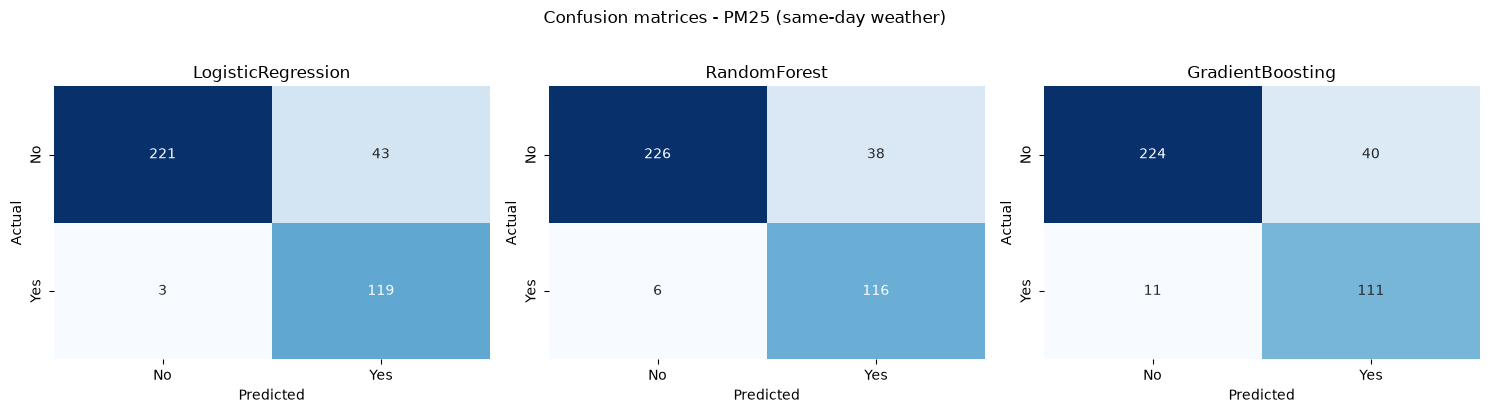

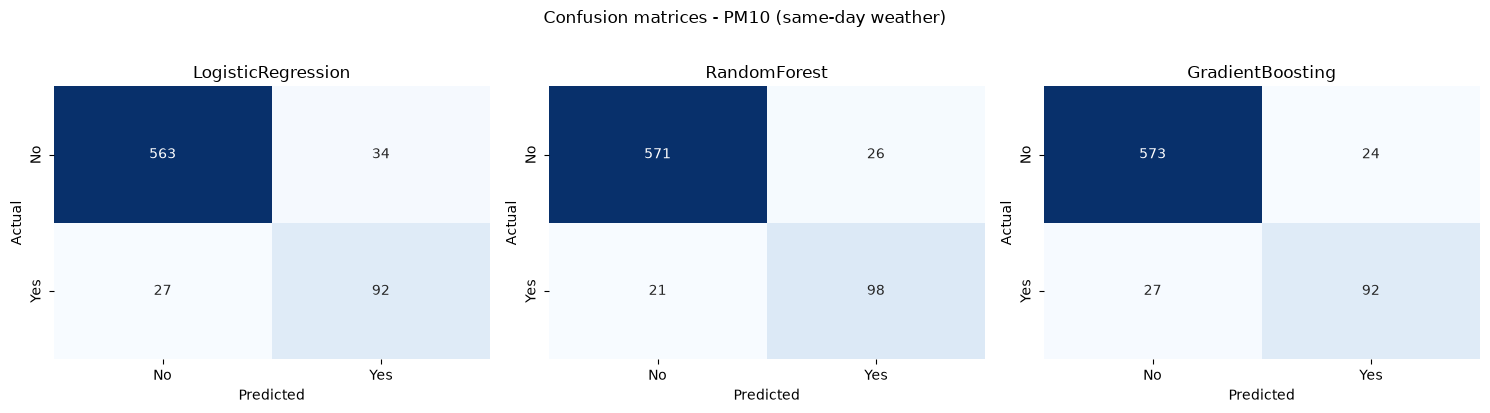

In [14]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]

    fig, axes = plt.subplots(1, len(entry["models"]), figsize=(5 * len(entry["models"]), 4))

    for ax, (name, (model, _, _)) in zip(axes, entry["models"].items()):
        cm = confusion_matrix(entry["y_test"], entry["predictions"][name])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                    xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
        ax.set_title(f"{name}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    plt.suptitle(f"Confusion matrices - {pollutant.upper()} (same-day weather)", y=1.02)
    plt.tight_layout()
    plt.show()


In [15]:
comparisons = {}

for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        entry = data[(pollutant, weather_mode)]
        split_idx = entry["split_idx"]

        comparison = pd.DataFrame({"date": entry["model_df"]["date"].iloc[split_idx:].reset_index(drop=True),
                                   "station_id": entry["model_df"]["station_id"].iloc[split_idx:].reset_index(drop=True),
                                   "y_test": entry["y_test"].reset_index(drop=True)})

        for name in entry["models"]:
            comparison[name + "_pred"] = entry["predictions"][name]
            comparison[name + "_proba"] = entry["probabilities"][name]

        comparisons[(pollutant, weather_mode)] = comparison

        best_cls = results_by_key[(pollutant, weather_mode)].drop(index="MajorityClass")["F1"].idxmax()
        entry["best_cls"] = best_cls

        print(f"\n{pollutant.upper()} [{weather_mode}]: best classifier by F1 = {best_cls}")

    display(comparisons[(pollutant, "same_day")].head(10))



PM25 [same_day]: best classifier by F1 = RandomForest

PM25 [t_minus_1]: best classifier by F1 = RandomForest


,date,station_id,y_test,LogisticRegression_pred,LogisticRegression_proba,RandomForest_pred,RandomForest_proba,GradientBoosting_pred,GradientBoosting_proba
0,2024-07-19,2919,0,0,0.072502,0,0.016667,0,0.025339
1,2024-07-19,2976,0,0,0.108336,0,0.163333,0,0.082145
2,2024-07-19,2977,0,0,0.062432,0,0.013333,0,0.016932
3,2024-07-19,2996,0,0,0.081035,0,0.026667,0,0.025339
4,2024-07-19,2978,0,0,0.056388,0,0.016667,0,0.016932
5,2024-07-20,2976,0,0,0.078556,0,0.183333,0,0.076255
6,2024-07-20,2919,0,0,0.058252,0,0.013333,0,0.028869
7,2024-07-20,2996,0,0,0.069607,0,0.070000,0,0.030604
8,2024-07-20,2977,0,0,0.058177,0,0.006667,0,0.027448
9,2024-07-20,2978,0,0,0.043334,0,0.006667,0,0.021596



PM10 [same_day]: best classifier by F1 = RandomForest

PM10 [t_minus_1]: best classifier by F1 = RandomForest


,date,station_id,y_test,LogisticRegression_pred,LogisticRegression_proba,RandomForest_pred,RandomForest_proba,GradientBoosting_pred,GradientBoosting_proba
0,2024-03-07,2919,0,0,0.186850,0,0.070000,0,0.041237
1,2024-03-07,2976,0,0,0.331362,0,0.166667,0,0.133634
2,2024-03-07,2979,0,0,0.247970,0,0.103333,0,0.070715
3,2024-03-08,2919,0,0,0.063458,0,0.186667,0,0.033274
4,2024-03-08,2979,0,0,0.101790,0,0.220000,0,0.043119
5,2024-03-08,2976,0,0,0.136367,0,0.353333,0,0.102329
6,2024-03-09,2976,0,0,0.381724,0,0.303333,0,0.128076
7,2024-03-09,2919,0,0,0.205133,0,0.240000,0,0.040186
8,2024-03-09,2979,0,0,0.303584,0,0.240000,0,0.055840
9,2024-03-10,2919,0,0,0.040615,0,0.106667,0,0.029892


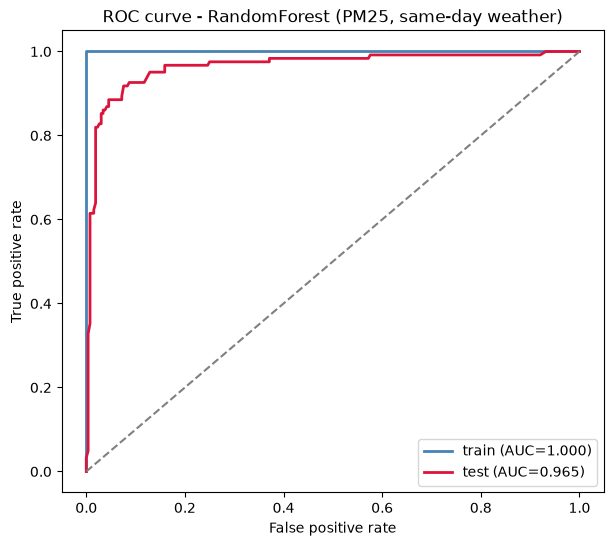

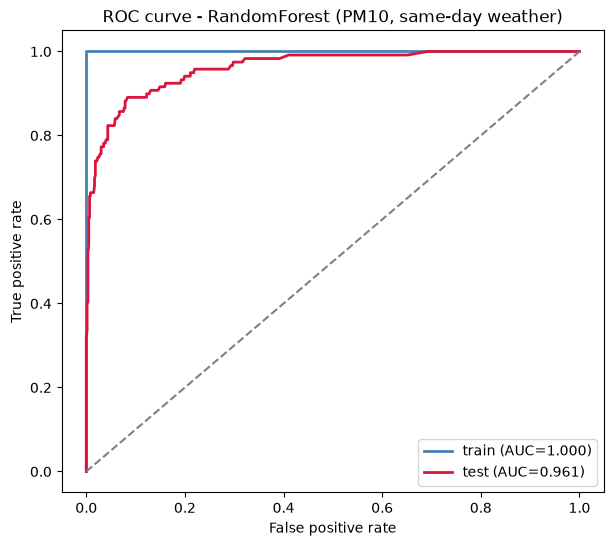

In [16]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    best_cls = entry["best_cls"]
    model, xtr, _ = entry["models"][best_cls]

    proba_train = model.predict_proba(xtr)[:, 1]
    proba_test = entry["probabilities"][best_cls]

    _, ax = plt.subplots(figsize=(7, 6))
    for label, proba, y_true, color in [("train", proba_train, entry["y_train"], "steelblue"),
                                        ("test", proba_test, entry["y_test"], "crimson")]:
        fpr, tpr, _ = roc_curve(y_true, proba)
        ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_true, proba):.3f})",
                color=color, linewidth=2)

    ax.plot([0, 1], [0, 1], "--", color="grey")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curve - {best_cls} ({pollutant.upper()}, same-day weather)")
    ax.legend()
    plt.show()



PM25 (RandomForest, same-day weather)


,feature,importance
0,pm25_lag_1,0.148262
3,pm25_rolling_3,0.086563
4,pm25_rolling_7,0.081660
6,pm25_rolling_std_7,0.051612
1,pm25_lag_2,0.050366
2,pm25_lag_3,0.035819
5,pm25_rolling_std_3,0.024174
32,diffuse_radiation_sum,0.021879
47,soil_temperature_7_to_28cm_mean,0.021742
53,soil_moisture_100_to_255cm_mean,0.020662


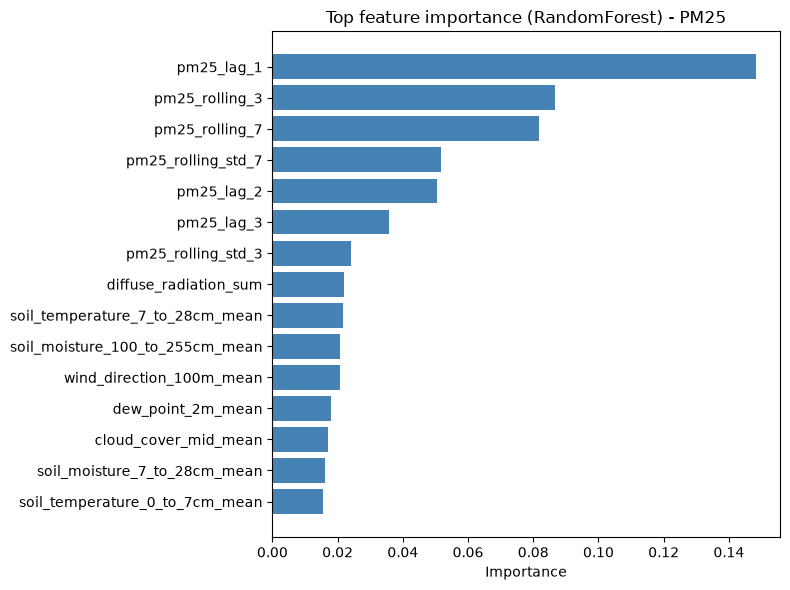


PM10 (RandomForest, same-day weather)


,feature,importance
0,pm10_lag_1,0.137856
3,pm10_rolling_3,0.082984
4,pm10_rolling_7,0.062655
1,pm10_lag_2,0.043239
6,pm10_rolling_std_7,0.037544
47,soil_temperature_7_to_28cm_mean,0.032290
39,wind_gusts_10m_max,0.031871
46,soil_temperature_0_to_7cm_mean,0.030398
2,pm10_lag_3,0.030117
41,wind_direction_100m_mean,0.023779


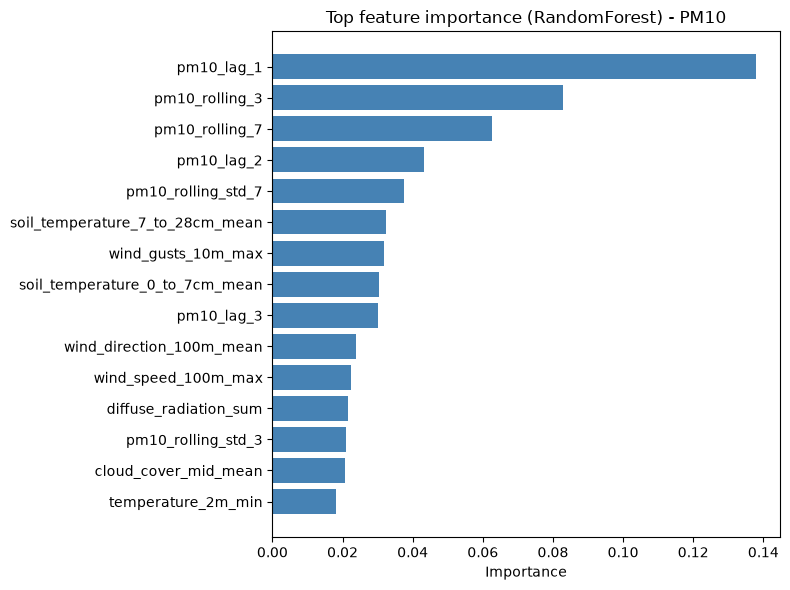

In [17]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    best_cls_model = entry["models"][entry["best_cls"]][0]

    if hasattr(best_cls_model, "feature_importances_"):
        importance = best_cls_model.feature_importances_
    else:
        importance = np.abs(best_cls_model.coef_)

    entry["importance"] = importance

    imp_df = pd.DataFrame({"feature": entry["X"].columns, "importance": importance}).sort_values("importance", ascending=False)

    print(f"\n{pollutant.upper()} ({entry['best_cls']}, same-day weather)")
    display(imp_df.head(15))

    plt.figure(figsize=(8, 6))
    plot_df = imp_df.head(15).iloc[::-1]
    plt.barh(plot_df["feature"], plot_df["importance"], color="steelblue")
    plt.xlabel("Importance")
    plt.title(f"Top feature importance ({entry['best_cls']}) - {pollutant.upper()}")
    plt.tight_layout()
    plt.show()


In [18]:
def get_factor_groups(pollutant, feature_names):
    return {
        "Previous pollution (lag)": [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS],
        "Previous pollution (rolling)": [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS] + [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS],
        "Temperature": [c for c in feature_names if "temperature" in c or "dew_point" in c],
        "Humidity": [c for c in feature_names if "humidity" in c or "vapour_pressure" in c],
        "Wind": [c for c in feature_names if "wind" in c and "category" not in c] + [c for c in feature_names if c.startswith("wind_")],
        "Precipitation": [c for c in feature_names if "precip" in c or "rain" in c or "snowfall" in c or "snow_depth" in c],
        "Pressure": [c for c in feature_names if "pressure" in c],
        "Clouds & radiation": [c for c in feature_names if "cloud" in c or "radiation" in c or "sunshine" in c or "et0" in c],
        "Season / calendar": [c for c in feature_names if "month" in c or "dow" in c or "weekend" in c],
        "Soil": [c for c in feature_names if c.startswith("soil")],
        "Wind category": [c for c in feature_names if c.startswith("wind_weak") or c.startswith("wind_moderate") or c.startswith("wind_strong")],
        "Weather code": [c for c in feature_names if "weather_code" in c],
    }


In [19]:
def group_importance(importance, feature_names, factor_groups):
    factor_importance = []

    for factor, cols in factor_groups.items():
        present = [c for c in cols if c in feature_names]
        if not present:
            continue

        vals = [importance[feature_names.index(c)] for c in present]
        factor_importance.append({
            "factor": factor,
            "n_features": len(present),
            "importance_max": float(np.max(vals)),
            "importance_mean": float(np.mean(vals)),
        })

    return pd.DataFrame(factor_importance).sort_values("importance_mean", ascending=False)


In [20]:
factor_tables = {}

for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    feature_names = list(entry["X"].columns)
    factor_df = group_importance(entry["importance"], feature_names, get_factor_groups(pollutant, feature_names))
    factor_tables[pollutant] = factor_df

    print(f"\n{pollutant.upper()} ({entry['best_cls']})")
    display(factor_df.round(4))



PM25 (RandomForest)


,factor,n_features,importance_max,importance_mean
0,Previous pollution (lag),3,0.1483,0.0781
1,Previous pollution (rolling),4,0.0866,0.0610
9,Soil,8,0.0217,0.0156
2,Temperature,9,0.0217,0.0147
7,Clouds & radiation,9,0.0219,0.0126
3,Humidity,4,0.0098,0.0094
6,Pressure,5,0.0098,0.0086
4,Wind,20,0.0206,0.0086
8,Season / calendar,5,0.0126,0.0048
5,Precipitation,5,0.0071,0.0039



PM10 (RandomForest)


,factor,n_features,importance_max,importance_mean
0,Previous pollution (lag),3,0.1379,0.0704
1,Previous pollution (rolling),4,0.0830,0.0510
2,Temperature,9,0.0323,0.0170
9,Soil,8,0.0323,0.0156
7,Clouds & radiation,9,0.0215,0.0139
4,Wind,20,0.0319,0.0131
6,Pressure,5,0.0105,0.0095
3,Humidity,4,0.0100,0.0092
5,Precipitation,5,0.0070,0.0046
8,Season / calendar,5,0.0097,0.0042


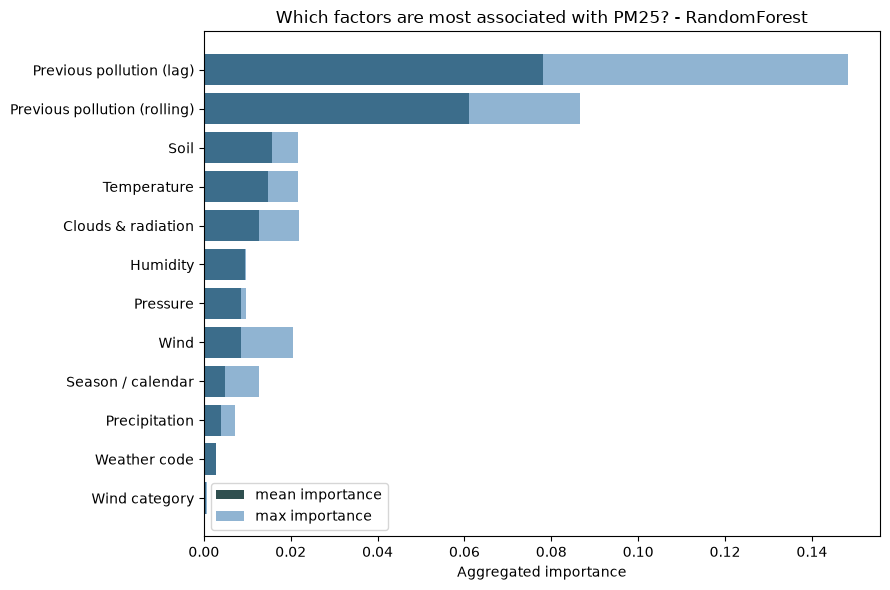

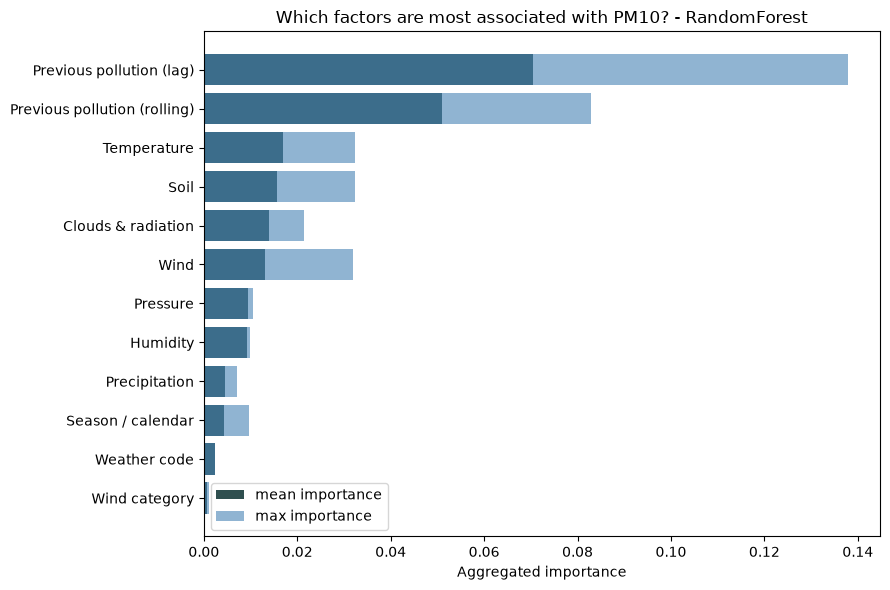

In [21]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    factor_df = factor_tables[pollutant]

    plt.figure(figsize=(9, 6))
    plot_df = factor_df.iloc[::-1]
    plt.barh(plot_df["factor"], plot_df["importance_mean"], color="darkslategray", label="mean importance")
    plt.barh(plot_df["factor"], plot_df["importance_max"], color="steelblue", alpha=0.6, label="max importance")
    plt.xlabel("Aggregated importance")
    plt.title(f"Which factors are most associated with {pollutant.upper()}? - {entry['best_cls']}")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [22]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    split_idx = entry["split_idx"]

    METRICS_OUT = PROCESSED_DIR / f"classification_metrics_{pollutant}.parquet"
    PRED_OUT = PROCESSED_DIR / f"classification_predictions_{pollutant}.parquet"
    PROBA_OUT = PROCESSED_DIR / f"classification_probabilities_{pollutant}.parquet"

    results_by_key[(pollutant, "same_day")].to_parquet(METRICS_OUT)
    comparisons[(pollutant, "same_day")].to_parquet(PRED_OUT, index=False)

    proba_df = pd.DataFrame(entry["probabilities"])
    proba_df["date"] = entry["model_df"]["date"].iloc[split_idx:].reset_index(drop=True)
    proba_df["station_id"] = entry["model_df"]["station_id"].iloc[split_idx:].reset_index(drop=True)
    proba_df.to_parquet(PROBA_OUT, index=False)

    print(f"Saved: {METRICS_OUT.name} (same_day weather variant)")
    print(f"Saved: {PRED_OUT.name} (same_day weather variant)")
    print(f"Saved: {PROBA_OUT.name} (same_day weather variant)")


Saved: classification_metrics_pm25.parquet (same_day weather variant)
Saved: classification_predictions_pm25.parquet (same_day weather variant)
Saved: classification_probabilities_pm25.parquet (same_day weather variant)
Saved: classification_metrics_pm10.parquet (same_day weather variant)
Saved: classification_predictions_pm10.parquet (same_day weather variant)
Saved: classification_probabilities_pm10.parquet (same_day weather variant)
